## Live solution of the $V(x) = \alpha x^4$ problem 

In [76]:
import sympy as sp

In [77]:
x = sp.symbols('x', real = True)
alpha = sp.symbols('alpha', real = True, positive = True)
beta = sp.symbols('beta', real = True, positive = True)
V = alpha * x**4

In [78]:
hbar, m = sp.symbols('hbar m', real = True, positive = True)
m,n = sp.symbols('m n', integer = True, positive = True)
psi_i = x**m*sp.exp(-beta*x**2)
psi_j = x**n*sp.exp(-beta*x**2)


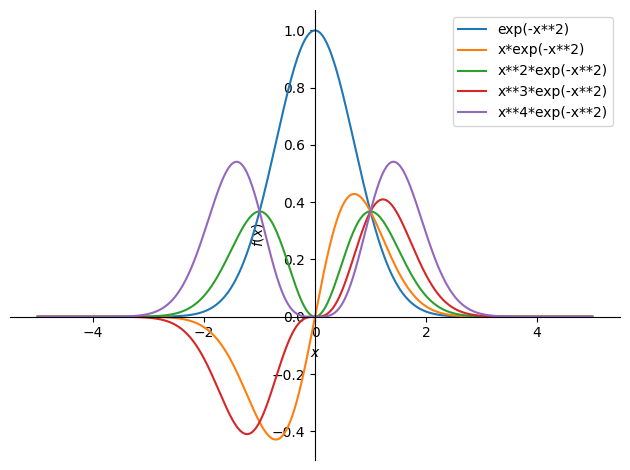

In [84]:
N_max = 5
basis = [x**i*sp.exp(-x**2) for i in range(N_max)]
sp.plot(*basis, (x, -5, 5),backend='matplotlib', legend = True)

In [70]:

S_ij = sp.integrate(psi_i * psi_j, (x, -sp.oo, sp.oo))
S_ij = sp.simplify(S_ij)
S_ij

2**(-m/2 - n/2 + 1/2)*beta**(-m/2 - n/2 - 1/2)*((-1)**(m + n) + 1)*gamma(m/2 + n/2 + 1/2)/4

In [74]:
H_ij = sp.integrate(psi_i * (-hbar**2/(2*m) * sp.diff(psi_j, x, x) + V * psi_j), (x, -sp.oo, sp.oo))
H_ij = sp.simplify(H_ij.doit())
H_ij.doit()

Piecewise((2**(-m/2 - n/2 + 1/2)*beta**(-m/2 - n/2 - 5/2)*((-1)**(m + n) + 1)*(alpha*m*gamma(m/2 + n/2 + 5/2) - 4*beta**3*hbar**2*n**2*gamma(m/2 + n/2 - 1/2) + 4*beta**3*hbar**2*n*gamma(m/2 + n/2 - 1/2) + 8*beta**3*hbar**2*n*gamma(m/2 + n/2 + 1/2) + 4*beta**3*hbar**2*gamma(m/2 + n/2 + 1/2) - 4*beta**3*hbar**2*gamma(m/2 + n/2 + 3/2))/(16*m), m + n > 1), (Piecewise(((-1)**(m + n - 2)*alpha*(2*beta)**(-m/2 - n/2 - 3/2)*gamma(m/2 + n/2 + 5/2)/(4*beta) - (-1)**(m + n - 2)*beta*hbar**2*(2*beta)**(-m/2 - n/2 - 1/2)*gamma(m/2 + n/2 + 3/2)/(2*m) + (-1)**(m + n - 2)*hbar**2*n*(2*beta)**(-m/2 - n/2 + 1/2)*gamma(m/2 + n/2 + 1/2)/(2*m) + (-1)**(m + n - 2)*hbar**2*(2*beta)**(-m/2 - n/2 + 1/2)*gamma(m/2 + n/2 + 1/2)/(4*m) - (-1)**(m + n - 2)*hbar**2*n**2*(2*beta)**(-m/2 - n/2 + 3/2)*gamma(m/2 + n/2 - 1/2)/(8*beta*m) + (-1)**(m + n - 2)*hbar**2*n*(2*beta)**(-m/2 - n/2 + 3/2)*gamma(m/2 + n/2 - 1/2)/(8*beta*m) + alpha*(2*beta)**(-m/2 - n/2 - 3/2)*gamma(m/2 + n/2 + 5/2)/(4*beta) - beta*hbar**2*(2*beta)**

In [86]:
import numpy as np
def get_HS(N):
    H = sp.Matrix.zeros(N, N)
    S = sp.Matrix.zeros(N, N)
    for i in range(N):
        psi_i = x**i*sp.exp(-beta*x**2)
        for j in range(N):
            psi_j = x**j*sp.exp(-beta*x**2)
            H[i, j] = sp.integrate(psi_i * (-hbar**2/(2*m) * sp.diff(psi_j, x, x) + V * psi_j), (x, -sp.oo, sp.oo)).simplify()
            S[i, j] = sp.integrate(psi_i * psi_j, (x, -sp.oo, sp.oo)).simplify()
    H = H.subs({m: 1, hbar: 1, beta: 1, alpha: 1})
    S = S.subs({m: 1, hbar: 1, beta: 1, alpha: 1})
    H = np.array(H).astype(np.float64)
    S = np.array(S).astype(np.float64)
    e,v = np.linalg.eig(np.linalg.inv(S) @ H)
    return e

In [88]:
N_max = 13
for n in range(1, N_max + 1):
    e = get_HS(n)
    print(f"N = {n}, Eigenvalues: {np.sort(e)}")

N = 1, Eigenvalues: [0.6875]
N = 2, Eigenvalues: [0.6875 2.4375]
N = 3, Eigenvalues: [0.68015974 2.4375     4.94484026]
N = 4, Eigenvalues: [0.68015974 2.42124162 4.94484026 8.20375838]
N = 5, Eigenvalues: [ 0.66853027  2.42124162  4.72445729  8.20375838 12.41951245]
N = 6, Eigenvalues: [ 0.66853027  2.39945406  4.72445729  7.37294119 12.41951245 17.79010476]
N = 7, Eigenvalues: [ 0.66807985  2.39945406  4.7157134   7.37294119 10.40840925 17.79010476
 24.45779749]
N = 8, Eigenvalues: [ 0.66807985  2.39383671  4.7157134   7.36664813 10.40840925 13.97605605
 24.45779749 32.51345911]
N = 9, Eigenvalues: [ 0.66803082  2.39383671  4.69907762  7.36664813 10.27408701 13.97605605
 18.27867144 32.51345911 42.01763311]
N = 10, Eigenvalues: [ 0.66803082  2.39375846  4.69907762  7.34618456 10.27408701 13.42301547
 18.27867144 23.50984802 42.01763311 53.01469349]
N = 11, Eigenvalues: [ 0.66799033  2.39375846  4.69691074  7.34618456 10.26866169 13.42301547
 16.89208473 23.50984802 29.80959083 53.014

In [58]:
import numpy as np
H = np.array(H).astype(np.float64)
S = np.array(S).astype(np.float64)
np.linalg.eig(np.linalg.inv(S) @ H)

EigResult(eigenvalues=array([0.68015974, 4.94484026, 2.4375    ]), eigenvectors=array([[-0.99275929,  0.25586965,  0.        ],
       [ 0.        ,  0.        ,  1.        ],
       [-0.12012071, -0.96671129,  0.        ]]))